<a href="https://colab.research.google.com/github/miriamamin1213-ux/3-Fold/blob/main/HecktorROC%26PRcurves.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!python HECKTOR_Combined_ROC_PR_Curves.py

python3: can't open file '/content/HECKTOR_Combined_ROC_PR_Curves.py': [Errno 2] No such file or directory


Checking coordinate counts...
ANN: 27 ROC points, 116 PR points — verified
CNN: 30 ROC points, 116 PR points — verified
GPT2: 27 ROC points, 115 PR points — verified
GPT2_LoRA: 28 ROC points, 114 PR points — verified

ROC-AUC calculated from supplied coordinates:
ANN: 0.755503
CNN: 0.760220
GPT2: 0.734277
GPT2_LoRA: 0.763365


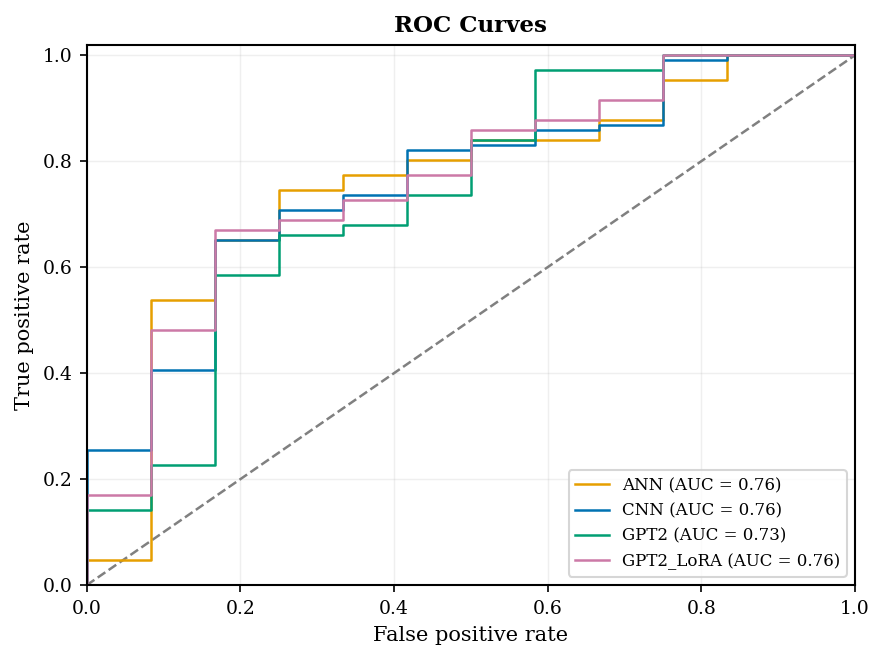

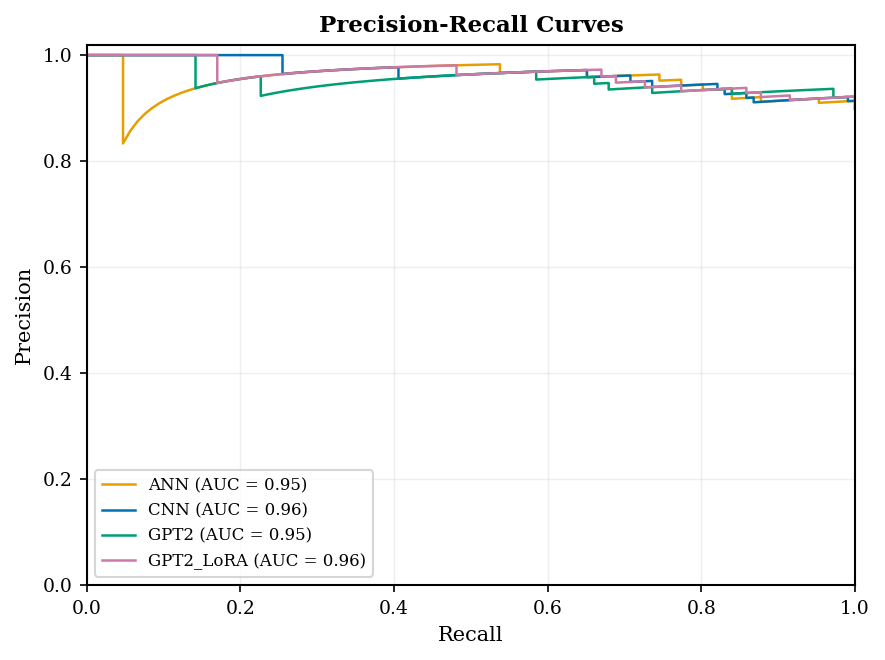

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# ============================================================
# HECKTOR: COMBINED ROC AND PRECISION-RECALL CURVES
# ============================================================

import os
import shutil
import zipfile

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import auc
from google.colab import files

# ============================================================
# ORIGINAL COORDINATES
# ROC format: (FPR, TPR)
# PR format:  (Recall, Precision)
# Thresholds are not needed to plot the curves.
# ============================================================

curves = {
    "ANN": {
        "roc": [
            (0.00000000, 0.00000000), (0.00000000, 0.00943400), (0.00000000, 0.04717000),
            (0.08333300, 0.04717000), (0.08333300, 0.40566000), (0.08333300, 0.42452800),
            (0.08333300, 0.53773600), (0.16666700, 0.53773600), (0.16666700, 0.65094300),
            (0.25000000, 0.65094300), (0.25000000, 0.66037700), (0.25000000, 0.67924500),
            (0.25000000, 0.74528300), (0.33333300, 0.74528300), (0.33333300, 0.76415100),
            (0.33333300, 0.77358500), (0.41666700, 0.77358500), (0.41666700, 0.80188700),
            (0.50000000, 0.80188700), (0.50000000, 0.83962300), (0.66666700, 0.83962300),
            (0.66666700, 0.87735800), (0.75000000, 0.87735800), (0.75000000, 0.95283000),
            (0.83333300, 0.95283000), (0.83333300, 1.00000000), (1.00000000, 1.00000000),
        ],
        "pr": [
            (1.00000000, 0.89830500), (1.00000000, 0.90598300), (1.00000000, 0.91379300),
            (0.99056600, 0.91304300), (0.98113200, 0.91228100), (0.97169800, 0.91150400),
            (0.96226400, 0.91071400), (0.95283000, 0.90991000), (0.95283000, 0.91818200),
            (0.94339600, 0.91743100), (0.93396200, 0.91666700), (0.92452800, 0.91588800),
            (0.91509400, 0.91509400), (0.90566000, 0.91428600), (0.89622600, 0.91346200),
            (0.88679200, 0.91262100), (0.87735800, 0.91176500), (0.87735800, 0.92079200),
            (0.86792500, 0.92000000), (0.85849100, 0.91919200), (0.84905700, 0.91836700),
            (0.83962300, 0.91752600), (0.83962300, 0.92708300), (0.83962300, 0.93684200),
            (0.83018900, 0.93617000), (0.82075500, 0.93548400), (0.81132100, 0.93478300),
            (0.80188700, 0.93406600), (0.80188700, 0.94444400), (0.79245300, 0.94382000),
            (0.78301900, 0.94318200), (0.77358500, 0.94252900), (0.77358500, 0.95348800),
            (0.76415100, 0.95294100), (0.74528300, 0.95180700), (0.74528300, 0.96341500),
            (0.73584900, 0.96296300), (0.72641500, 0.96250000), (0.71698100, 0.96202500),
            (0.70754700, 0.96153800), (0.69811300, 0.96103900), (0.68867900, 0.96052600),
            (0.67924500, 0.96000000), (0.66037700, 0.95890400), (0.65094300, 0.95833300),
            (0.65094300, 0.97183100), (0.64150900, 0.97142900), (0.63207500, 0.97101400),
            (0.62264200, 0.97058800), (0.61320800, 0.97014900), (0.60377400, 0.96969700),
            (0.59434000, 0.96923100), (0.58490600, 0.96875000), (0.57547200, 0.96825400),
            (0.56603800, 0.96774200), (0.55660400, 0.96721300), (0.54717000, 0.96666700),
            (0.53773600, 0.96610200), (0.53773600, 0.98275900), (0.52830200, 0.98245600),
            (0.51886800, 0.98214300), (0.50943400, 0.98181800), (0.50000000, 0.98148100),
            (0.49056600, 0.98113200), (0.48113200, 0.98076900), (0.47169800, 0.98039200),
            (0.46226400, 0.98000000), (0.45283000, 0.97959200), (0.44339600, 0.97916700),
            (0.43396200, 0.97872300), (0.42452800, 0.97826100), (0.40566000, 0.97727300),
            (0.39622600, 0.97674400), (0.38679200, 0.97619000), (0.37735800, 0.97561000),
            (0.36792500, 0.97500000), (0.35849100, 0.97435900), (0.34905700, 0.97368400),
            (0.33962300, 0.97297300), (0.33018900, 0.97222200), (0.32075500, 0.97142900),
            (0.31132100, 0.97058800), (0.30188700, 0.96969700), (0.29245300, 0.96875000),
            (0.28301900, 0.96774200), (0.27358500, 0.96666700), (0.26415100, 0.96551700),
            (0.25471700, 0.96428600), (0.24528300, 0.96296300), (0.23584900, 0.96153800),
            (0.22641500, 0.96000000), (0.21698100, 0.95833300), (0.20754700, 0.95652200),
            (0.19811300, 0.95454500), (0.18867900, 0.95238100), (0.17924500, 0.95000000),
            (0.16981100, 0.94736800), (0.16037700, 0.94444400), (0.15094300, 0.94117600),
            (0.14150900, 0.93750000), (0.13207500, 0.93333300), (0.12264200, 0.92857100),
            (0.11320800, 0.92307700), (0.10377400, 0.91666700), (0.09434000, 0.90909100),
            (0.08490600, 0.90000000), (0.07547200, 0.88888900), (0.06603800, 0.87500000),
            (0.05660400, 0.85714300), (0.04717000, 0.83333300), (0.04717000, 1.00000000),
            (0.03773600, 1.00000000), (0.02830200, 1.00000000), (0.01886800, 1.00000000),
            (0.00943400, 1.00000000), (0.00000000, 1.00000000),
        ],
    },

    "CNN": {
        "roc": [
            (0.00000000, 0.00000000), (0.00000000, 0.00943400), (0.00000000, 0.25471700),
            (0.08333300, 0.25471700), (0.08333300, 0.33962300), (0.08333300, 0.35849100),
            (0.08333300, 0.40566000), (0.16666700, 0.40566000), (0.16666700, 0.43396200),
            (0.16666700, 0.45283000), (0.16666700, 0.65094300), (0.25000000, 0.65094300),
            (0.25000000, 0.70754700), (0.33333300, 0.70754700), (0.33333300, 0.73584900),
            (0.41666700, 0.73584900), (0.41666700, 0.77358500), (0.41666700, 0.79245300),
            (0.41666700, 0.82075500), (0.50000000, 0.82075500), (0.50000000, 0.83018900),
            (0.58333300, 0.83018900), (0.58333300, 0.85849100), (0.66666700, 0.85849100),
            (0.66666700, 0.86792500), (0.75000000, 0.86792500), (0.75000000, 0.99056600),
            (0.83333300, 0.99056600), (0.83333300, 1.00000000), (1.00000000, 1.00000000),
        ],
        "pr": [
            (1.00000000, 0.89830500), (1.00000000, 0.90598300), (1.00000000, 0.91379300),
            (0.99056600, 0.91304300), (0.99056600, 0.92105300), (0.98113200, 0.92035400),
            (0.97169800, 0.91964300), (0.96226400, 0.91891900), (0.95283000, 0.91818200),
            (0.94339600, 0.91743100), (0.93396200, 0.91666700), (0.92452800, 0.91588800),
            (0.91509400, 0.91509400), (0.90566000, 0.91428600), (0.89622600, 0.91346200),
            (0.88679200, 0.91262100), (0.87735800, 0.91176500), (0.86792500, 0.91089100),
            (0.86792500, 0.92000000), (0.85849100, 0.91919200), (0.85849100, 0.92857100),
            (0.84905700, 0.92783500), (0.83962300, 0.92708300), (0.83018900, 0.92631600),
            (0.83018900, 0.93617000), (0.82075500, 0.93548400), (0.82075500, 0.94565200),
            (0.81132100, 0.94505500), (0.80188700, 0.94444400), (0.79245300, 0.94382000),
            (0.77358500, 0.94252900), (0.76415100, 0.94186000), (0.75471700, 0.94117600),
            (0.74528300, 0.94047600), (0.73584900, 0.93975900), (0.73584900, 0.95122000),
            (0.72641500, 0.95061700), (0.71698100, 0.95000000), (0.70754700, 0.94936700),
            (0.70754700, 0.96153800), (0.69811300, 0.96103900), (0.68867900, 0.96052600),
            (0.67924500, 0.96000000), (0.66981100, 0.95945900), (0.66037700, 0.95890400),
            (0.65094300, 0.95833300), (0.65094300, 0.97183100), (0.64150900, 0.97142900),
            (0.63207500, 0.97101400), (0.62264200, 0.97058800), (0.61320800, 0.97014900),
            (0.60377400, 0.96969700), (0.59434000, 0.96923100), (0.58490600, 0.96875000),
            (0.57547200, 0.96825400), (0.56603800, 0.96774200), (0.55660400, 0.96721300),
            (0.54717000, 0.96666700), (0.53773600, 0.96610200), (0.52830200, 0.96551700),
            (0.51886800, 0.96491200), (0.50943400, 0.96428600), (0.50000000, 0.96363600),
            (0.49056600, 0.96296300), (0.48113200, 0.96226400), (0.47169800, 0.96153800),
            (0.46226400, 0.96078400), (0.45283000, 0.96000000), (0.43396200, 0.95833300),
            (0.42452800, 0.95744700), (0.41509400, 0.95652200), (0.40566000, 0.95555600),
            (0.40566000, 0.97727300), (0.39622600, 0.97674400), (0.38679200, 0.97619000),
            (0.37735800, 0.97561000), (0.36792500, 0.97500000), (0.35849100, 0.97435900),
            (0.33962300, 0.97297300), (0.33018900, 0.97222200), (0.32075500, 0.97142900),
            (0.31132100, 0.97058800), (0.30188700, 0.96969700), (0.29245300, 0.96875000),
            (0.28301900, 0.96774200), (0.27358500, 0.96666700), (0.26415100, 0.96551700),
            (0.25471700, 0.96428600), (0.25471700, 1.00000000), (0.24528300, 1.00000000),
            (0.23584900, 1.00000000), (0.22641500, 1.00000000), (0.21698100, 1.00000000),
            (0.20754700, 1.00000000), (0.19811300, 1.00000000), (0.18867900, 1.00000000),
            (0.17924500, 1.00000000), (0.16981100, 1.00000000), (0.16037700, 1.00000000),
            (0.15094300, 1.00000000), (0.14150900, 1.00000000), (0.13207500, 1.00000000),
            (0.12264200, 1.00000000), (0.11320800, 1.00000000), (0.10377400, 1.00000000),
            (0.09434000, 1.00000000), (0.08490600, 1.00000000), (0.07547200, 1.00000000),
            (0.06603800, 1.00000000), (0.05660400, 1.00000000), (0.04717000, 1.00000000),
            (0.03773600, 1.00000000), (0.02830200, 1.00000000), (0.01886800, 1.00000000),
            (0.00943400, 1.00000000), (0.00000000, 1.00000000),
        ],
    },

    "GPT2": {
        "roc": [
            (0.00000000, 0.00000000), (0.00000000, 0.00943400), (0.00000000, 0.14150900),
            (0.08333300, 0.14150900), (0.08333300, 0.22641500), (0.16666700, 0.22641500),
            (0.16666700, 0.58490600), (0.25000000, 0.58490600), (0.25000000, 0.59434000),
            (0.25000000, 0.61320800), (0.25000000, 0.66037700), (0.33333300, 0.66037700),
            (0.33333300, 0.67924500), (0.41666700, 0.67924500), (0.41666700, 0.68867900),
            (0.41666700, 0.70754700), (0.41666700, 0.73584900), (0.50000000, 0.73584900),
            (0.50000000, 0.75471700), (0.50000000, 0.81132100), (0.50000000, 0.83018900),
            (0.50000000, 0.83962300), (0.58333300, 0.83962300), (0.58333300, 0.97169800),
            (0.75000000, 0.97169800), (0.75000000, 1.00000000), (1.00000000, 1.00000000),
        ],
        "pr": [
            (1.00000000, 0.89830500), (1.00000000, 0.90598300), (1.00000000, 0.91379300),
            (1.00000000, 0.92173900), (0.99056600, 0.92105300), (0.98113200, 0.92035400),
            (0.97169800, 0.91964300), (0.97169800, 0.92792800), (0.97169800, 0.93636400),
            (0.96226400, 0.93578000), (0.95283000, 0.93518500), (0.94339600, 0.93457900),
            (0.93396200, 0.93396200), (0.92452800, 0.93333300), (0.91509400, 0.93269200),
            (0.90566000, 0.93203900), (0.89622600, 0.93137300), (0.88679200, 0.93069300),
            (0.87735800, 0.93000000), (0.86792500, 0.92929300), (0.85849100, 0.92857100),
            (0.84905700, 0.92783500), (0.83962300, 0.92708300), (0.83962300, 0.93684200),
            (0.83018900, 0.93617000), (0.81132100, 0.93478300), (0.80188700, 0.93406600),
            (0.79245300, 0.93333300), (0.78301900, 0.93258400), (0.77358500, 0.93181800),
            (0.76415100, 0.93103400), (0.75471700, 0.93023300), (0.73584900, 0.92857100),
            (0.73584900, 0.93975900), (0.72641500, 0.93902400), (0.71698100, 0.93827200),
            (0.70754700, 0.93750000), (0.68867900, 0.93589700), (0.67924500, 0.93506500),
            (0.67924500, 0.94736800), (0.66981100, 0.94666700), (0.66037700, 0.94594600),
            (0.66037700, 0.95890400), (0.65094300, 0.95833300), (0.64150900, 0.95774600),
            (0.63207500, 0.95714300), (0.62264200, 0.95652200), (0.61320800, 0.95588200),
            (0.59434000, 0.95454500), (0.58490600, 0.95384600), (0.58490600, 0.96875000),
            (0.57547200, 0.96825400), (0.56603800, 0.96774200), (0.55660400, 0.96721300),
            (0.54717000, 0.96666700), (0.53773600, 0.96610200), (0.52830200, 0.96551700),
            (0.51886800, 0.96491200), (0.50943400, 0.96428600), (0.50000000, 0.96363600),
            (0.49056600, 0.96296300), (0.48113200, 0.96226400), (0.47169800, 0.96153800),
            (0.46226400, 0.96078400), (0.45283000, 0.96000000), (0.44339600, 0.95918400),
            (0.43396200, 0.95833300), (0.42452800, 0.95744700), (0.41509400, 0.95652200),
            (0.40566000, 0.95555600), (0.39622600, 0.95454500), (0.38679200, 0.95348800),
            (0.37735800, 0.95238100), (0.36792500, 0.95122000), (0.35849100, 0.95000000),
            (0.34905700, 0.94871800), (0.33962300, 0.94736800), (0.33018900, 0.94594600),
            (0.32075500, 0.94444400), (0.31132100, 0.94285700), (0.30188700, 0.94117600),
            (0.29245300, 0.93939400), (0.28301900, 0.93750000), (0.27358500, 0.93548400),
            (0.26415100, 0.93333300), (0.25471700, 0.93103400), (0.24528300, 0.92857100),
            (0.23584900, 0.92592600), (0.22641500, 0.92307700), (0.22641500, 0.96000000),
            (0.21698100, 0.95833300), (0.20754700, 0.95652200), (0.19811300, 0.95454500),
            (0.18867900, 0.95238100), (0.17924500, 0.95000000), (0.16981100, 0.94736800),
            (0.16037700, 0.94444400), (0.15094300, 0.94117600), (0.14150900, 0.93750000),
            (0.14150900, 1.00000000), (0.13207500, 1.00000000), (0.12264200, 1.00000000),
            (0.11320800, 1.00000000), (0.10377400, 1.00000000), (0.09434000, 1.00000000),
            (0.08490600, 1.00000000), (0.07547200, 1.00000000), (0.06603800, 1.00000000),
            (0.05660400, 1.00000000), (0.04717000, 1.00000000), (0.03773600, 1.00000000),
            (0.02830200, 1.00000000), (0.01886800, 1.00000000), (0.00943400, 1.00000000),
            (0.00000000, 1.00000000),
        ],
    },

    "GPT2_LoRA": {
        "roc": [
            (0.00000000, 0.00000000), (0.00000000, 0.00943396), (0.00000000, 0.16981132),
            (0.08333333, 0.16981132), (0.08333333, 0.48113208), (0.16666667, 0.48113208),
            (0.16666667, 0.63207547), (0.16666667, 0.66037736), (0.16666667, 0.66981132),
            (0.25000000, 0.66981132), (0.25000000, 0.68867925), (0.33333333, 0.68867925),
            (0.33333333, 0.70754717), (0.33333333, 0.72641509), (0.41666667, 0.72641509),
            (0.41666667, 0.74528302), (0.41666667, 0.77358491), (0.50000000, 0.77358491),
            (0.50000000, 0.80188679), (0.50000000, 0.82075472), (0.50000000, 0.85849057),
            (0.58333333, 0.85849057), (0.58333333, 0.87735849), (0.66666667, 0.87735849),
            (0.66666667, 0.91509434), (0.75000000, 0.91509434), (0.75000000, 1.00000000),
            (1.00000000, 1.00000000),
        ],
        "pr": [
            (1.00000000, 0.89830508), (1.00000000, 0.90598291), (1.00000000, 0.91379310),
            (1.00000000, 0.92173913), (0.99056604, 0.92105263), (0.98113208, 0.92035398),
            (0.97169811, 0.91964286), (0.96226415, 0.91891892), (0.95283019, 0.91818182),
            (0.94339623, 0.91743119), (0.93396226, 0.91666667), (0.92452830, 0.91588785),
            (0.91509434, 0.91509434), (0.91509434, 0.92380952), (0.90566038, 0.92307692),
            (0.89622642, 0.92233010), (0.88679245, 0.92156863), (0.87735849, 0.92079208),
            (0.87735849, 0.93000000), (0.86792453, 0.92929293), (0.85849057, 0.92857143),
            (0.85849057, 0.93814433), (0.84905660, 0.93750000), (0.83962264, 0.93684211),
            (0.83018868, 0.93617021), (0.82075472, 0.93548387), (0.80188679, 0.93406593),
            (0.79245283, 0.93333333), (0.78301887, 0.93258427), (0.77358491, 0.93181818),
            (0.77358491, 0.94252874), (0.76415094, 0.94186047), (0.75471698, 0.94117647),
            (0.74528302, 0.94047619), (0.72641509, 0.93902439), (0.72641509, 0.95061728),
            (0.71698113, 0.95000000), (0.70754717, 0.94936709), (0.68867925, 0.94805195),
            (0.68867925, 0.96052632), (0.67924528, 0.96000000), (0.66981132, 0.95945946),
            (0.66981132, 0.97260274), (0.66037736, 0.97222222), (0.63207547, 0.97101449),
            (0.62264151, 0.97058824), (0.61320755, 0.97014925), (0.60377358, 0.96969697),
            (0.59433962, 0.96923077), (0.58490566, 0.96875000), (0.57547170, 0.96825397),
            (0.56603774, 0.96774194), (0.55660377, 0.96721311), (0.54716981, 0.96666667),
            (0.53773585, 0.96610169), (0.52830189, 0.96551724), (0.51886792, 0.96491228),
            (0.50943396, 0.96428571), (0.50000000, 0.96363636), (0.49056604, 0.96296296),
            (0.48113208, 0.96226415), (0.48113208, 0.98076923), (0.47169811, 0.98039216),
            (0.46226415, 0.98000000), (0.45283019, 0.97959184), (0.44339623, 0.97916667),
            (0.43396226, 0.97872340), (0.42452830, 0.97826087), (0.41509434, 0.97777778),
            (0.40566038, 0.97727273), (0.39622642, 0.97674419), (0.38679245, 0.97619048),
            (0.37735849, 0.97560976), (0.36792453, 0.97500000), (0.35849057, 0.97435897),
            (0.34905660, 0.97368421), (0.33962264, 0.97297297), (0.33018868, 0.97222222),
            (0.32075472, 0.97142857), (0.31132075, 0.97058824), (0.30188679, 0.96969697),
            (0.29245283, 0.96875000), (0.28301887, 0.96774194), (0.27358491, 0.96666667),
            (0.26415094, 0.96551724), (0.25471698, 0.96428571), (0.24528302, 0.96296296),
            (0.23584906, 0.96153846), (0.22641509, 0.96000000), (0.21698113, 0.95833333),
            (0.20754717, 0.95652174), (0.19811321, 0.95454545), (0.18867925, 0.95238095),
            (0.17924528, 0.95000000), (0.16981132, 0.94736842), (0.16981132, 1.00000000),
            (0.16037736, 1.00000000), (0.15094340, 1.00000000), (0.14150943, 1.00000000),
            (0.13207547, 1.00000000), (0.12264151, 1.00000000), (0.11320755, 1.00000000),
            (0.10377358, 1.00000000), (0.09433962, 1.00000000), (0.08490566, 1.00000000),
            (0.07547170, 1.00000000), (0.06603774, 1.00000000), (0.05660377, 1.00000000),
            (0.04716981, 1.00000000), (0.03773585, 1.00000000), (0.02830189, 1.00000000),
            (0.01886792, 1.00000000), (0.00943396, 1.00000000), (0.00000000, 1.00000000),
        ],
    },
}


# ============================================================
# VERIFY THAT EVERY ORIGINAL POINT IS INCLUDED
# ============================================================

expected_counts = {
    "ANN":       {"roc": 27, "pr": 116},
    "CNN":       {"roc": 30, "pr": 116},
    "GPT2":      {"roc": 27, "pr": 115},
    "GPT2_LoRA": {"roc": 28, "pr": 114},
}

print("Checking coordinate counts...")

for model_name, expected in expected_counts.items():
    actual_roc = len(curves[model_name]["roc"])
    actual_pr = len(curves[model_name]["pr"])

    assert actual_roc == expected["roc"], (
        f"{model_name} ROC point count incorrect: "
        f"{actual_roc} instead of {expected['roc']}"
    )

    assert actual_pr == expected["pr"], (
        f"{model_name} PR point count incorrect: "
        f"{actual_pr} instead of {expected['pr']}"
    )

    print(
        f"{model_name}: {actual_roc} ROC points, "
        f"{actual_pr} PR points — verified"
    )


# ============================================================
# CALCULATE ROC-AUC FROM THE PROVIDED ROC COORDINATES
# ============================================================

print("\nROC-AUC calculated from supplied coordinates:")

for model_name, data in curves.items():
    roc_points = np.asarray(data["roc"], dtype=float)
    roc_auc = auc(roc_points[:, 0], roc_points[:, 1])
    print(f"{model_name}: {roc_auc:.6f}")


# ============================================================
# COMBINED ROC AND PRECISION-RECALL CURVES
# ============================================================

colours = {
    "CNN": "#0072B2",
    "ANN": "#E69F00",
    "GPT2": "#009E73",
    "GPT2_LoRA": "#CC79A7"
}

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "legend.fontsize": 8,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.linewidth": 1.0,
    "figure.dpi": 150
})


# ---------------- ROC CURVES ----------------

fig, ax = plt.subplots(figsize=(6, 4.5))

# Chance diagonal (without legend label)
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="grey",
    linewidth=1.2,
    label="_nolegend_"
)

for model_name, data in curves.items():

    roc_points = np.asarray(data["roc"], dtype=float)
    fpr = roc_points[:, 0]
    tpr = roc_points[:, 1]

    roc_auc = auc(fpr, tpr)

    ax.plot(
        fpr,
        tpr,
        color=colours[model_name],
        linewidth=1.2,
        linestyle="-",
        label=f"{model_name} (AUC = {roc_auc:.2f})"
    )

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.set_title("ROC Curves", fontsize=11, fontweight="bold")
ax.grid(True, alpha=0.2, linewidth=0.7)
ax.legend(loc="lower right", fontsize=8, frameon=True)

plt.tight_layout()

plt.savefig(
    "HECKTOR_Combined_ROC_Curves.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "HECKTOR_Combined_ROC_Curves.pdf",
    bbox_inches="tight"
)

plt.show()


# ---------------- PRECISION-RECALL CURVES ----------------

fig, ax = plt.subplots(figsize=(6, 4.5))

for model_name, data in curves.items():

    pr_points = np.asarray(data["pr"], dtype=float)
    recall = pr_points[:, 0]
    precision = pr_points[:, 1]

    pr_auc = auc(recall, precision)

    ax.plot(
        recall,
        precision,
        color=colours[model_name],
        linewidth=1.2,
        linestyle="-",
        label=f"{model_name} (AUC = {pr_auc:.2f})"
    )

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.set_title(
    "Precision-Recall Curves",
    fontsize=11,
    fontweight="bold"
)

ax.grid(True, alpha=0.2, linewidth=0.7)
ax.legend(loc="lower left", fontsize=8, frameon=True)

plt.tight_layout()

plt.savefig(
    "HECKTOR_Combined_PR_Curves.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "HECKTOR_Combined_PR_Curves.pdf",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# DOWNLOAD BOTH PNG GRAPHS
# ============================================================

files.download("HECKTOR_Combined_ROC_Curves.png")
files.download("HECKTOR_Combined_PR_Curves.png")